# 06 — Resultados

**Qué hace.** Junta los resultados de los notebooks 02–05 en las tablas finales de cada tarea y en las figuras que usan el README y la app.

**Qué lee.** `rutas.resultados_dir` y, para la sección 1, las transcripciones cacheadas en `rutas.cache_dir` (`data/cache/transcripciones/<corrida>/<clip>.json`).

**Qué produce.** Las tablas de resultados de Task 1 y Task 2 para el README y los archivos que carga la app (la app no recalcula nada).

**Corre en local, sin GPU.** Nada de este notebook transcribe: todas las secciones leen el texto de la caché. La sección 1 lee el texto que el notebook 02 guardó en la caché y recalcula el WER y el CER con la normalización actual de `src/normalizacion.py`. **Estas son las métricas definitivas de la capa de transcripción**; las de `wer_por_clip.csv` y `mediciones_transcripcion.csv` se calcularon en Colab con la normalización de ese momento. El tiempo y la VRAM sí son de Colab: se midieron al transcribir y se leen de cada JSON.

**Versión 1 y versión 2 de las reglas.** Las secciones 2 a 4 son la evaluación con audio real del PR #7 (**versión 1**) y se ejecutan con las reglas de ese momento. De su tabla de causas salió la corrección de formato de la sección 5 (**versión 2**), que es la definitiva: con ella se escriben los archivos de la sección 8.

**Corrida principal.** La configuración por defecto del motor: `asr.modelo` (large-v3), la precisión de `cuda` (float16) y `asr.glosario_mecanismo` (hotwords). Las demás corridas de la caché se muestran como comparación. El **techo** es la misma extracción sobre las referencias (el texto del guion), como en `03_extraccion`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(RAIZ))
from src.config import cargar_config
from src.metricas import intervalo_bootstrap, wer_cer
from src.normalizacion import con_reglas, normalizar_texto
from src.transcripcion import cargar_cache, id_corrida

cfg = cargar_config()
rutas, asr = cfg["rutas"], cfg["asr"]
VERSION_1 = cfg["normalizacion"]["version_1"]   # el formato de Whisper apagado: las reglas del PR #7
pd.set_option("display.max_colwidth", None)

## 1. Task 1: capa de transcripción

Modelos, precisiones, CPU/GPU y glosario, con intervalos.

### 1.1 La caché

`cargar_cache` lee todos los JSON de `data/cache/`. El device, la precisión y las versiones de cada corrida son los que reportó la librería en Colab y quedaron guardados en el JSON. La última línea comprueba que en este proceso no se cargó faster-whisper ni CTranslate2: las métricas salen del texto guardado, no de transcribir otra vez.

In [2]:
corridas = cargar_cache(rutas["cache_dir"])
clips = sorted({clip for rs in corridas.values() for clip in rs})
referencias = {clip: (rutas["referencias_dir"] / cfg["archivos"]["patron_referencia"].format(clip=clip)).read_text(encoding="utf-8")
               for clip in clips}

cache = pd.DataFrame([{
    "corrida": corrida, "modelo": r0["modelo"], "precision": r0["compute_type"],
    "device": "/".join(sorted({r["device"] for r in rs.values()})), "glosario": r0["glosario"] or "sin",
    "clips": len(rs), "transcrito": min(r["fecha"] for r in rs.values())[:16].replace("T", " "),
    "faster_whisper": r0["versiones"]["faster_whisper"], "ctranslate2": r0["versiones"]["ctranslate2"],
} for corrida, rs in corridas.items() for r0 in [next(iter(rs.values()))]])
assert not {"faster_whisper", "ctranslate2"} & set(sys.modules), "este notebook no debe transcribir"
print(f"{sum(cache.clips)} transcripciones de {len(cache)} corridas, sin cargar faster-whisper ni CTranslate2")
cache

62 transcripciones de 7 corridas, sin cargar faster-whisper ni CTranslate2


,corrida,modelo,precision,device,glosario,clips,transcrito,faster_whisper,ctranslate2
0,large-v3_float16_cuda_hotwords,large-v3,float16,cuda,hotwords,10,2026-11-01 22:56,1.2.1,4.8.4
1,large-v3_float16_cuda_initial_prompt,large-v3,float16,cuda,initial_prompt,10,2026-11-01 22:53,1.2.1,4.8.4
2,large-v3_float16_cuda_sin-glosario,large-v3,float16,cuda,sin,10,2026-11-01 22:44,1.2.1,4.8.4
3,large-v3_int8_cuda_sin-glosario,large-v3,int8_float16,cuda,sin,10,2026-11-01 22:49,1.2.1,4.8.4
4,small_float16_cuda_sin-glosario,small,float16,cuda,sin,10,2026-11-01 22:45,1.2.1,4.8.4
5,small_int8_cpu_sin-glosario,small,int8_float32,cpu,sin,2,2026-11-01 22:52,1.2.1,4.8.4
6,small_int8_cuda_sin-glosario,small,int8_float16,cuda,sin,10,2026-11-01 22:46,1.2.1,4.8.4


### 1.2 Antes y después de los cambios de normalización

- **Los cambios.** Son dos, y los dos corrigen cómo escribe Whisper, no lo que oye:
  - **Cifras mixtas** (PR #6). Whisper escribe "10 mil" donde la referencia dice "diez mil". Antes, text2num leía el "mil" suelto: "10 mil" quedaba "10 1000" y la referencia "10000", así que el WER contaba **dos errores** (una sustitución y una inserción) por una palabra bien oída. Ahora un multiplicador detrás de una cifra se multiplica (`config.yaml → normalizacion.multiplicadores`; casos en el notebook 03, sección 1.1).
  - **Símbolos de moneda** (versión 2, sección 5). Whisper escribe "$1.800" donde la referencia dice "mil ochocientos dólares". Antes el "$" se borraba como puntuación y el WER contaba "dólares" como palabra perdida. Ahora "$1.800" queda "1800 dólares" (`normalizacion.simbolos_moneda`; casos en el notebook 03, sección 1.5). Los otros ajustes de formato de la versión 2 no cambian el WER: `normalizar_texto` ya quitaba el separador de miles y el guion.
- **Antes.** Es la misma normalización con `multiplicadores` vacío y el formato de Whisper apagado (`normalizacion.version_1`). El assert comprueba que con ella se reproducen **exactamente** las 62 filas de `wer_por_clip.csv` calculadas en Colab: la caché es el mismo texto que midió el notebook 02 y la única diferencia entre antes y después son estos dos cambios.
- **Después.** La normalización actual: son las métricas definitivas.

In [3]:
ANTES = {**cfg["normalizacion"], **VERSION_1, "multiplicadores": {}}

filas = []
for corrida, rs in corridas.items():
    for clip, r in rs.items():
        antes, despues = wer_cer(referencias[clip], r["texto"], ANTES), wer_cer(referencias[clip], r["texto"])
        filas.append({"corrida": corrida, "clip": clip, "modelo": r["modelo"], "precision": r["compute_type"],
                      "device": r["device"], "glosario": r["glosario"] or "sin",
                      "wer_antes": antes["wer"], "wer": despues["wer"], "cer_antes": antes["cer"], "cer": despues["cer"],
                      "duracion_min": round(r["duracion_audio_s"] / 60, 2), "tiempo_s": r["tiempo_s"],
                      "s_por_min_audio": r["segundos_por_minuto"], "vram_pico_mb": r["vram_pico_mb"]})
por_clip = pd.DataFrame(filas)

colab = pd.read_csv(rutas["wer_por_clip"]).merge(por_clip, on=["corrida", "clip"], suffixes=("_colab", ""))
assert len(colab) == len(por_clip) == 62
assert (colab["wer_colab"] == colab["wer_antes"].round(4)).all() and (colab["cer_colab"] == colab["cer_antes"].round(4)).all()
print("OK: con la normalización anterior se reproducen las 62 filas de wer_por_clip.csv calculadas en Colab")

cambian = por_clip[por_clip["wer"].round(4) != por_clip["wer_antes"].round(4)]
print(f"Cambian {len(cambian)} de {len(por_clip)} filas; clips afectados: {sorted(set(cambian['clip']))}")
cambian[["corrida", "clip", "wer_antes", "wer", "cer_antes", "cer"]].round(4)

OK: con la normalización anterior se reproducen las 62 filas de wer_por_clip.csv calculadas en Colab
Cambian 10 de 62 filas; clips afectados: ['e2', 'e3']


,corrida,clip,wer_antes,wer,cer_antes,cer
1,large-v3_float16_cuda_hotwords,e2,0.0120,0.0090,0.0063,0.0021
2,large-v3_float16_cuda_hotwords,e3,0.0336,0.0268,0.0130,0.0119
11,large-v3_float16_cuda_initial_prompt,e2,0.0150,0.0120,0.0078,0.0037
12,large-v3_float16_cuda_initial_prompt,e3,0.0403,0.0336,0.0169,0.0158
21,large-v3_float16_cuda_sin-glosario,e2,0.0419,0.0389,0.0303,0.0261
22,large-v3_float16_cuda_sin-glosario,e3,0.0537,0.0470,0.0265,0.0254
31,large-v3_int8_cuda_sin-glosario,e2,0.0419,0.0389,0.0303,0.0261
32,large-v3_int8_cuda_sin-glosario,e3,0.0570,0.0503,0.0226,0.0214
42,small_float16_cuda_sin-glosario,e3,0.0839,0.0671,0.0248,0.0203
54,small_int8_cuda_sin-glosario,e3,0.0805,0.0638,0.0277,0.0231


Dónde está la diferencia, en los dos clips afectados: el mismo fragmento de la referencia y de la transcripción de `large-v3` float16, normalizados antes y después.

In [4]:
corrida = id_corrida(asr["modelo"], asr["compute_type"]["cuda"], "cuda", None)
for clip, inicio in [("e3", "estoy entre"), ("e2", "alrededor de")]:
    for nombre, reglas in [("antes", ANTES), ("después", None)]:
        for fuente, texto in [("referencia", referencias[clip]), ("large-v3", corridas[corrida][clip]["texto"])]:
            normalizado = normalizar_texto(texto, reglas)
            i = normalizado.find(inicio)
            print(f"{clip} · {nombre:>8} · {fuente:<10}: {normalizado[i:i + 45]}")

e3 ·    antes · referencia: estoy entre 9 y 10000 soles idealmente 9500 b
e3 ·    antes · large-v3  : estoy entre 9 y 10 1000 soles idealmente 9500
e3 ·  después · referencia: estoy entre 9 y 10000 soles idealmente 9500 b
e3 ·  después · large-v3  : estoy entre 9 y 10000 soles idealmente 9500 b
e2 ·    antes · referencia: alrededor de 1800 dólares al mes considerando
e2 ·    antes · large-v3  : alrededor de 1800 al mes considerando que es 
e2 ·  después · referencia: alrededor de 1800 dólares al mes considerando
e2 ·  después · large-v3  : alrededor de 1800 dólares al mes considerando


### 1.3 Por corrida

- **WER y CER del corpus**: todas las palabras de los clips de la corrida juntas (jiwer sobre las listas), antes y después.
- **IC 95 %**: bootstrap del WER medio por clip, remuestreando los clips. Con 10 clips el intervalo es ancho.
- **Velocidad y VRAM**: las mediciones de Colab. `vram_corrida_mb` es el pico menos la memoria que ya estaba ocupada antes de cargar el modelo (556 MB del contexto CUDA).

In [5]:
def por_corrida(corrida):
    rs = corridas[corrida]
    cs = list(rs)
    refs, hips = [referencias[c] for c in cs], [rs[c]["texto"] for c in cs]
    antes, despues = wer_cer(refs, hips, ANTES), wer_cer(refs, hips)
    bajo, alto = intervalo_bootstrap(por_clip.loc[por_clip["corrida"] == corrida, "wer"].tolist())
    picos = [r["vram_pico_mb"] for r in rs.values() if r["vram_pico_mb"] is not None]
    bases = [r["vram_base_mb"] for r in rs.values() if r["vram_base_mb"] is not None]
    r0 = rs[cs[0]]
    return {"corrida": corrida, "modelo": r0["modelo"], "precision": r0["compute_type"], "device": r0["device"],
            "glosario": r0["glosario"] or "sin", "clips": len(cs),
            "wer_antes": round(antes["wer"], 4), "wer": round(despues["wer"], 4),
            "ic95_wer_clip": (round(bajo, 4), round(alto, 4)),
            "cer_antes": round(antes["cer"], 4), "cer": round(despues["cer"], 4),
            "s_por_min_audio": round(sum(r["tiempo_s"] for r in rs.values()) / (sum(r["duracion_audio_s"] for r in rs.values()) / 60), 2),
            "vram_pico_mb": max(picos) if picos else None,
            "vram_corrida_mb": round(max(picos) - min(bases), 1) if picos and bases else None}


metricas = pd.DataFrame([por_corrida(c) for c in corridas]).sort_values(["device", "modelo", "glosario", "precision"],
                                                                        ascending=[False, True, False, True])
mediciones_colab = pd.read_csv(rutas["mediciones_transcripcion"]).set_index("corrida")
assert (mediciones_colab.loc[metricas["corrida"], "wer"].values == metricas["wer_antes"].values).all()
metricas.reset_index(drop=True)

,corrida,modelo,precision,device,glosario,clips,wer_antes,wer,ic95_wer_clip,cer_antes,cer,s_por_min_audio,vram_pico_mb,vram_corrida_mb
0,large-v3_float16_cuda_sin-glosario,large-v3,float16,cuda,sin,10,0.0363,0.0352,"(0.029, 0.0449)",0.0253,0.0246,6.60,5366.2,4810.0
1,large-v3_int8_cuda_sin-glosario,large-v3,int8_float16,cuda,sin,10,0.0414,0.0402,"(0.033, 0.0528)",0.0280,0.0273,6.38,3862.2,3306.0
2,large-v3_float16_cuda_initial_prompt,large-v3,float16,cuda,initial_prompt,10,0.0398,0.0387,"(0.029, 0.0505)",0.0263,0.0256,8.12,5462.2,4906.0
3,large-v3_float16_cuda_hotwords,large-v3,float16,cuda,hotwords,10,0.0371,0.0359,"(0.0263, 0.0564)",0.0259,0.0252,7.81,5558.2,5002.0
4,small_float16_cuda_sin-glosario,small,float16,cuda,sin,10,0.0576,0.0557,"(0.0439, 0.069)",0.0216,0.0210,1.91,1334.2,778.0
5,small_int8_cuda_sin-glosario,small,int8_float16,cuda,sin,10,0.0588,0.0568,"(0.0458, 0.0702)",0.0229,0.0223,1.97,1046.2,490.0
6,small_int8_cpu_sin-glosario,small,int8_float32,cpu,sin,2,0.0446,0.0446,"(0.0233, 0.0593)",0.0141,0.0141,31.92,556.2,0.0


### 1.4 Modelo × precisión en GPU, por clip

WER definitivo de cada clip, sin glosario.

In [6]:
sin_glosario = por_clip[(por_clip["device"] == "cuda") & (por_clip["glosario"] == "sin")]
sin_glosario.pivot_table(index="clip", columns=["modelo", "precision"], values="wer").round(3)

modelo    large-v3                small             
precision  float16 int8_float16 float16 int8_float16
clip                                                
e1           0.019        0.022   0.059        0.062
e2           0.039        0.039   0.039        0.030
e3           0.047        0.050   0.067        0.064
e4           0.035        0.035   0.062        0.066
e5           0.032        0.029   0.064        0.068
l1           0.023        0.019   0.023        0.027
l2           0.033        0.061   0.023        0.033
l3           0.067        0.073   0.067        0.067
l4           0.041        0.046   0.071        0.082
l5           0.026        0.053   0.090        0.085

### 1.5 ¿Cambia el texto entre float16 e int8?

Se compara el texto normalizado de las dos precisiones del mismo modelo, clip por clip, y el WER de una contra la otra.

In [7]:
p0, p1 = asr["precisiones_comparacion"][:2]
filas = []
for modelo in asr["modelos_comparacion"]:
    a, b = corridas[id_corrida(modelo, p0, "cuda", None)], corridas[id_corrida(modelo, p1, "cuda", None)]
    for clip in a:
        filas.append({"modelo": modelo, "clip": clip,
                      "texto_identico": normalizar_texto(a[clip]["texto"]) == normalizar_texto(b[clip]["texto"]),
                      "wer_entre_precisiones": round(wer_cer(a[clip]["texto"], b[clip]["texto"])["wer"], 4),
                      f"wer_{p0}": round(wer_cer(referencias[clip], a[clip]["texto"])["wer"], 4),
                      f"wer_{p1}": round(wer_cer(referencias[clip], b[clip]["texto"])["wer"], 4)})
precisiones = pd.DataFrame(filas)
precisiones.groupby("modelo").agg(clips_identicos=("texto_identico", "sum"), clips=("clip", "count"),
                                  wer_entre_precisiones_medio=("wer_entre_precisiones", "mean")).round(4)

,clips_identicos,clips,wer_entre_precisiones_medio
modelo,,,
large-v3,1,10,0.0155
small,0,10,0.0175


### 1.6 CPU contra GPU

El mismo modelo y la misma precisión (`asr.cpu`) en los dos devices, en los clips de `asr.cpu.clips`. El device es el que reportó la librería al transcribir.

In [8]:
cpu = asr["cpu"]
en_cpu = corridas[id_corrida(cpu["modelo"], cpu["compute_type"], "cpu", None)]
en_gpu = corridas[id_corrida(cpu["modelo"], cpu["compute_type"], "cuda", None)]
cpu_gpu = pd.DataFrame([{
    "clip": clip, "device_cpu": en_cpu[clip]["device"], "device_gpu": en_gpu[clip]["device"],
    "s_por_min_cpu": en_cpu[clip]["segundos_por_minuto"], "s_por_min_gpu": en_gpu[clip]["segundos_por_minuto"],
    "veces_mas_rapido_gpu": round(en_cpu[clip]["tiempo_s"] / en_gpu[clip]["tiempo_s"], 1),
    "texto_identico": normalizar_texto(en_cpu[clip]["texto"]) == normalizar_texto(en_gpu[clip]["texto"]),
    "wer_cpu": round(wer_cer(referencias[clip], en_cpu[clip]["texto"])["wer"], 4),
    "wer_gpu": round(wer_cer(referencias[clip], en_gpu[clip]["texto"])["wer"], 4),
} for clip in cpu["clips"]])
assert (cpu_gpu["device_cpu"] == "cpu").all() and (cpu_gpu["device_gpu"] == "cuda").all()
cpu_gpu

,clip,device_cpu,device_gpu,s_por_min_cpu,s_por_min_gpu,veces_mas_rapido_gpu,texto_identico,wer_cpu,wer_gpu
0,e1,cpu,cuda,35.103,2.432,14.4,False,0.0593,0.0620
1,l1,cpu,cuda,28.458,1.940,14.7,False,0.0233,0.0272


### 1.7 Glosario: initial_prompt contra hotwords

- **Diferencia pareada**: WER del clip con el mecanismo menos WER del mismo clip sin glosario (`large-v3` float16). Negativa es mejora.
- **IC 95 %**: bootstrap de la diferencia media, remuestreando los clips; antes y después del cambio de normalización.
- **Términos**: de los términos del glosario que aparecen en las referencias, cuántos aparecen también en la transcripción (los dos textos normalizados).
- **Diferencia con Colab en el cuarto decimal del IC "antes".** Es el mismo cálculo con la misma semilla, pero el bootstrap depende del orden de los valores: en Colab los clips iban en el orden de la corrida (primero e1 y l1, de la prueba rápida) y aquí van ordenados. La diferencia media sí es idéntica.

In [9]:
GLOSARIO = [*asr["glosario"]["tecnologias"], *asr["glosario"]["restaurante"]]
precision = asr["compute_type"]["cuda"]
base = id_corrida(asr["modelo"], precision, "cuda", None)


def terminos(texto):
    t = f" {normalizar_texto(texto)} "
    return {g for g in GLOSARIO if f" {normalizar_texto(g)} " in t}


wer_de = por_clip.set_index(["corrida", "clip"])
filas = []
for mecanismo in ["sin", *asr["glosario_mecanismos_comparacion"]]:
    corrida = base if mecanismo == "sin" else id_corrida(asr["modelo"], precision, "cuda", mecanismo)
    rs = corridas[corrida]
    fila = {"mecanismo": mecanismo, "wer_corpus": metricas.set_index("corrida").loc[corrida, "wer"]}
    if mecanismo != "sin":
        for cuando, columna in [("antes", "wer_antes"), ("después", "wer")]:
            dif = [wer_de.loc[(corrida, c), columna] - wer_de.loc[(base, c), columna] for c in rs]
            bajo, alto = intervalo_bootstrap(dif)
            fila[f"dif_media_{cuando}"] = round(sum(dif) / len(dif), 4)
            fila[f"ic95_{cuando}"] = (round(bajo, 4), round(alto, 4))
        fila["clips_mejoran"], fila["clips_empeoran"] = sum(d < 0 for d in dif), sum(d > 0 for d in dif)
    dichos = {c: terminos(referencias[c]) for c in rs}
    fila["terminos_bien"] = f"{sum(len(dichos[c] & terminos(r['texto'])) for c, r in rs.items())} de {sum(map(len, dichos.values()))}"
    fila["terminos_perdidos"] = sorted({t for c, r in rs.items() for t in dichos[c] - terminos(r["texto"])})
    filas.append(fila)
glosario = pd.DataFrame(filas)
glosario

,mecanismo,wer_corpus,terminos_bien,terminos_perdidos,dif_media_antes,ic95_antes,dif_media_después,ic95_después,clips_mejoran,clips_empeoran
0,sin,0.0352,39 de 40,[Nagios],NaN,NaN,NaN,NaN,NaN,NaN
1,initial_prompt,0.0387,39 de 40,[Plin],0.0031,"(-0.0093, 0.017)",0.0031,"(-0.0093, 0.017)",4.0,4.0
2,hotwords,0.0359,40 de 40,[],0.0042,"(-0.0083, 0.0171)",0.0042,"(-0.0083, 0.0171)",4.0,6.0


### 1.8 Clips con el WER más alto, y exportar

Primero en la configuración del motor (`asr.modelo`, la precisión de `cuda` y `asr.glosario_mecanismo`), después en todas las corridas. Al final se escriben las tablas definitivas: `metricas_transcripcion.csv` (una fila por corrida) y `metricas_por_clip.csv` (una por corrida y clip).

In [10]:
motor = id_corrida(asr["modelo"], asr["compute_type"]["cuda"], "cuda", asr["glosario_mecanismo"])
print("Configuración del motor:", motor)
display(por_clip[por_clip["corrida"] == motor].sort_values("wer", ascending=False)[["clip", "wer", "cer"]].round(4).head(5))
por_clip.sort_values("wer", ascending=False)[["corrida", "clip", "wer", "cer"]].round(4).head(8)

Configuración del motor: large-v3_float16_cuda_hotwords


,clip,wer,cer
8,l4,0.0867,0.0726
7,l3,0.0725,0.0656
3,e4,0.0586,0.0415
6,l2,0.0469,0.0327
9,l5,0.0370,0.0277


,corrida,clip,wer,cer
49,small_float16_cuda_sin-glosario,l5,0.0899,0.0382
8,large-v3_float16_cuda_hotwords,l4,0.0867,0.0726
61,small_int8_cuda_sin-glosario,l5,0.0847,0.0372
60,small_int8_cuda_sin-glosario,l4,0.0816,0.0452
7,large-v3_float16_cuda_hotwords,l3,0.0725,0.0656
37,large-v3_int8_cuda_sin-glosario,l3,0.0725,0.0598
48,small_float16_cuda_sin-glosario,l4,0.0714,0.0415
18,large-v3_float16_cuda_initial_prompt,l4,0.0714,0.0471


In [11]:
metricas.to_csv(rutas["metricas_transcripcion"], index=False)
por_clip.round(4).to_csv(rutas["metricas_por_clip"], index=False)
print("Escrito:", rutas["metricas_transcripcion"].relative_to(RAIZ), "y", rutas["metricas_por_clip"].relative_to(RAIZ))

Escrito: data/resultados/metricas_transcripcion.csv y data/resultados/metricas_por_clip.csv


## 2. Capa de registro con audio real (versión 1)

> **Versión 1.** Las secciones 2 a 4 son la evaluación del PR #7, con las reglas de ese momento. Se ejecutan dentro de `con_reglas(VERSION_1)`, que apaga el formato de Whisper de la versión 2 (`config.yaml → normalizacion.version_1`), y la sección 5.1 comprueba que reproducen exactamente las tablas que se publicaron entonces (`*_v1.csv`). Se dejan como estaban porque de aquí salió la corrección: la tabla de causas de la 2.5 mostró que casi todos los fallos venían de cómo escribe Whisper. La versión 2 está en la sección 5.

La extracción por reglas y la verificación de `03_extraccion` se corren ahora sobre el texto que produjo faster-whisper, en cada corrida de la caché y para los 10 clips. Nada se transcribe otra vez y las reglas no se tocan: los fallos que aparecen aquí se reportan, no se corrigen.

### 2.1 Extraer y verificar cada corrida

Una fila por corrida, clip y campo. En los campos que son listas (`tecnologias`, `items`), el estado de verificación es el peor de sus elementos.

In [12]:
from src.extraccion_reglas import extraer
from src.metricas import aciertos, error_absoluto, ground_truth, intervalo_wilson, macro_f1
from src.verificacion import verificar

ESQUEMA = {"e": "entrevista", "l": "pedido"}
CAMPOS = [*cfg["esquemas"]["entrevista"]["campos"], *cfg["esquemas"]["pedido"]["campos"]]
ESTADOS = cfg["verificacion"]
PRINCIPAL = id_corrida(asr["modelo"], asr["compute_type"]["cuda"], "cuda", asr["glosario_mecanismo"])
TECHO = "referencias"
gt = {**ground_truth("entrevista"), **ground_truth("pedido")}
textos = {TECHO: {clip: " ".join(t.split()) for clip, t in referencias.items()}} | {
    corrida: {clip: r["texto"] for clip, r in rs.items()} for corrida, rs in corridas.items()}
ORDEN = [TECHO, PRINCIPAL, *[c for c in metricas["corrida"] if c != PRINCIPAL]]


def mostrar(valor):
    """Forma compacta de un valor para las tablas (la misma de 03_extraccion)."""
    if isinstance(valor, list) and valor and isinstance(valor[0], dict):
        return "; ".join(f"{i['cantidad']}× {i['producto']} {i['tamano']} @{i['precio_unitario']}" for i in valor)
    if isinstance(valor, dict):
        return f"{valor['monto']} {valor['moneda']}"
    if isinstance(valor, list):
        return ", ".join(valor)
    return valor


def resumir_estado(estado):
    """Un estado por campo: en las listas, el peor de sus elementos."""
    if not isinstance(estado, list):
        return estado
    planos = [e["item"] if isinstance(e, dict) else e for e in estado]
    for peor in (ESTADOS["etiqueta_no_verificado"], ESTADOS["etiqueta_no_mencionado"]):
        if peor in planos:
            return peor
    return ESTADOS["etiqueta_verificado"] if planos else ESTADOS["etiqueta_no_mencionado"]


def extraer_y_verificar():
    """Registro y verificación de cada corrida y clip, con las reglas vigentes."""
    extraidos, filas = {}, []
    for corrida, por_clip_texto in textos.items():
        for clip, texto in por_clip_texto.items():
            esquema = ESQUEMA[clip[0]]
            campos = extraer(texto, esquema)
            estados = verificar(campos, texto)
            extraidos[corrida, clip] = campos
            acierta = aciertos({k: v["valor"] for k, v in campos.items()}, gt[clip], esquema)
            filas += [{"corrida": corrida, "clip": clip, "esquema": esquema, "campo": campo, "acierta": acierta[campo],
                       "estado": resumir_estado(estados[campo]), "extraido": mostrar(dato["valor"]),
                       "ground_truth": mostrar(gt[clip][campo])} for campo, dato in campos.items()]
    return extraidos, pd.DataFrame(filas)


with con_reglas(VERSION_1):
    extraidos, registro = extraer_y_verificar()
assert registro[registro["corrida"] == TECHO]["acierta"].all(), "el techo de 03_extraccion es 60 de 60"
print(f"Corrida principal: {PRINCIPAL}")
registro.groupby("corrida", sort=False)["acierta"].agg(aciertos="sum", campos="count").reindex(ORDEN)

Corrida principal: large-v3_float16_cuda_hotwords


,aciertos,campos
corrida,,
referencias,60,60
large-v3_float16_cuda_hotwords,50,60
large-v3_float16_cuda_sin-glosario,50,60
large-v3_int8_cuda_sin-glosario,50,60
large-v3_float16_cuda_initial_prompt,49,60
small_float16_cuda_sin-glosario,40,60
small_int8_cuda_sin-glosario,44,60
small_int8_cpu_sin-glosario,9,12


### 2.2 Exactitud por campo

Para la corrida principal, con el intervalo de Wilson al 95 %. **Con 5 clips por campo el intervalo es muy ancho**: 5 de 5 da [0.57, 1] y 2 de 5, [0.12, 0.77]. La tabla siguiente compara todas las corridas como aciertos sobre clips.

In [13]:
def exactitud(corrida, registro):
    g = registro[registro["corrida"] == corrida].groupby("campo", sort=False)["acierta"]
    return pd.DataFrame({"aciertos": g.sum(), "n": g.count()}).reindex(CAMPOS)


principal = exactitud(PRINCIPAL, registro)
principal["exactitud"] = principal["aciertos"] / principal["n"]
principal["ic95_wilson"] = [tuple(round(x, 2) for x in intervalo_wilson(a, n)) for a, n in zip(principal["aciertos"], principal["n"])]
principal.insert(0, "techo", exactitud(TECHO, registro).apply(lambda f: f"{f['aciertos']}/{f['n']}", axis=1))
principal.round(2)

,techo,aciertos,n,exactitud,ic95_wilson
campo,,,,,
anios_experiencia,5/5,5,5,1.0,"(0.57, 1.0)"
ultimo_puesto,5/5,3,5,0.6,"(0.23, 0.88)"
tecnologias,5/5,5,5,1.0,"(0.57, 1.0)"
pretension_salarial,5/5,1,5,0.2,"(0.04, 0.62)"
disponibilidad,5/5,5,5,1.0,"(0.57, 1.0)"
nivel_ingles,5/5,5,5,1.0,"(0.57, 1.0)"
items,5/5,5,5,1.0,"(0.57, 1.0)"
promocion,5/5,5,5,1.0,"(0.57, 1.0)"
descuento,5/5,5,5,1.0,"(0.57, 1.0)"


In [14]:
comparacion = pd.DataFrame({c: exactitud(c, registro).apply(lambda f: f"{f['aciertos']}/{f['n']}" if f["n"] else "—", axis=1)
                            for c in ORDEN})
comparacion.loc["total"] = [f"{registro.loc[registro['corrida'] == c, 'acierta'].sum()}/{(registro['corrida'] == c).sum()}" for c in ORDEN]
comparacion

,referencias,large-v3_float16_cuda_hotwords,large-v3_float16_cuda_sin-glosario,large-v3_int8_cuda_sin-glosario,large-v3_float16_cuda_initial_prompt,small_float16_cuda_sin-glosario,small_int8_cuda_sin-glosario,small_int8_cpu_sin-glosario
campo,,,,,,,,
anios_experiencia,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1
ultimo_puesto,5/5,3/5,3/5,3/5,3/5,4/5,4/5,0/1
tecnologias,5/5,5/5,5/5,5/5,5/5,1/5,2/5,0/1
pretension_salarial,5/5,1/5,1/5,1/5,1/5,1/5,1/5,0/1
disponibilidad,5/5,5/5,5/5,5/5,5/5,3/5,4/5,1/1
nivel_ingles,5/5,5/5,5/5,5/5,5/5,4/5,4/5,1/1
items,5/5,5/5,5/5,5/5,5/5,3/5,4/5,1/1
promocion,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1
descuento,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1


`small_int8_cpu_sin-glosario` tiene solo 2 clips (e1 y l1): es la corrida de CPU contra GPU, no una corrida completa.

### 2.3 macro F1 de `nivel_ingles` y error absoluto de los numéricos

El error absoluto se mide solo donde hay predicción; `sin_prediccion` cuenta los clips en que la regla no devolvió valor, que son fallos aunque no sumen error.

In [15]:
clases = cfg["esquemas"]["entrevista"]["clases"]["nivel_ingles"]
numericos = {
    "anios_experiencia": lambda r: r["anios_experiencia"],
    "pretension_salarial (monto)": lambda r: r["pretension_salarial"]["monto"] if r["pretension_salarial"] else None,
    "total_dicho": lambda r: r["total_dicho"],
    "descuento": lambda r: r["descuento"],
}
filas = []
for corrida in ORDEN:
    clips_corrida = sorted(textos[corrida])
    entrevistas = [c for c in clips_corrida if c.startswith("e")]
    fila = {"corrida": corrida,
            "macro_f1_nivel_ingles": round(macro_f1([gt[c]["nivel_ingles"] for c in entrevistas],
                                                    [extraidos[corrida, c]["nivel_ingles"]["valor"] for c in entrevistas], clases), 2),
            "n_entrevistas": len(entrevistas)}
    for nombre, valor in numericos.items():
        cs = [c for c in clips_corrida if nombre.split()[0] in gt[c]]
        errores = error_absoluto([valor(gt[c]) for c in cs], [valor({k: v["valor"] for k, v in extraidos[corrida, c].items()}) for c in cs])
        medidos = [e for e in errores if e is not None]
        fila[f"{nombre}: error medio"] = round(sum(medidos) / len(medidos), 1) if medidos else None
        fila[f"{nombre}: sin_prediccion"] = f"{errores.count(None)}/{len(cs)}"
    filas.append(fila)
numericos_tabla = pd.DataFrame(filas).set_index("corrida")
numericos_tabla.T

corrida,referencias,large-v3_float16_cuda_hotwords,large-v3_float16_cuda_sin-glosario,large-v3_int8_cuda_sin-glosario,large-v3_float16_cuda_initial_prompt,small_float16_cuda_sin-glosario,small_int8_cuda_sin-glosario,small_int8_cpu_sin-glosario
macro_f1_nivel_ingles,1.0,1.0,1.0,1.0,1.0,0.89,0.89,1.0
n_entrevistas,5,5,5,5,5,5,5,1
anios_experiencia: error medio,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
anios_experiencia: sin_prediccion,0/5,0/5,0/5,0/5,0/5,0/5,0/5,0/1
pretension_salarial (monto): error medio,0.0,250.0,250.0,250.0,250.0,0.0,0.0,NaN
pretension_salarial (monto): sin_prediccion,0/5,3/5,3/5,3/5,3/5,4/5,4/5,1/1
total_dicho: error medio,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
total_dicho: sin_prediccion,0/5,0/5,0/5,0/5,0/5,0/5,0/5,0/1
descuento: error medio,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
descuento: sin_prediccion,0/5,0/5,0/5,0/5,0/5,0/5,0/5,0/1


### 2.4 Estado de verificación

Cuántos campos de la corrida principal quedan en cada estado, y el cruce con la exactitud. La pregunta importante es la diagonal que falla: **un campo errado que queda `verificado`** da una falsa seguridad, porque la verificación solo comprueba que el valor aparezca literal en la transcripción, no que sea el correcto.

In [16]:
display(registro[registro["corrida"] == PRINCIPAL].pivot_table(index="campo", columns="estado", values="clip", aggfunc="count", fill_value=0).reindex(CAMPOS))
cruce = registro[registro["corrida"].isin([TECHO, PRINCIPAL])].pivot_table(
    index=["corrida", "acierta"], columns="estado", values="clip", aggfunc="count", fill_value=0)
cruce

estado,no_mencionado,sin_verificar,verificado
campo,,,
anios_experiencia,0,1,4
ultimo_puesto,0,0,5
tecnologias,0,0,5
pretension_salarial,3,0,2
disponibilidad,0,0,5
nivel_ingles,0,0,5
items,0,0,5
promocion,0,0,5
descuento,0,0,5


estado                                  no_mencionado  sin_verificar  \
corrida                        acierta                                 
large-v3_float16_cuda_hotwords False                6              0   
                               True                 0              1   
referencias                    True                 0              1   

estado                                  verificado  
corrida                        acierta              
large-v3_float16_cuda_hotwords False             4  
                               True             49  
referencias                    True             59

### 2.5 Qué se pierde por el audio, y por qué

Los campos que fallan en la corrida principal y aciertan en el techo, con el fragmento de la transcripción y el de la referencia. El assert comprueba que la lista de fragmentos cubre exactamente los fallos: si una corrida nueva cambia los fallos, esta celda se detiene en vez de mostrar ejemplos viejos.

In [17]:
import re

fragmentos = {  # (clip, campo) -> palabra de la que se muestra el contexto
    ("e1", "pretension_salarial"): "pretensión", ("e2", "pretension_salarial"): "alrededor",
    ("e3", "pretension_salarial"): "idealmente", ("e5", "pretension_salarial"): "gano",
    ("e1", "ultimo_puesto"): "semi", ("e4", "ultimo_puesto"): "junior",
    ("l1", "direccion_entrega"): "Cedros", ("l2", "direccion_entrega"): "Gardenias",
    ("l3", "direccion_entrega"): "Halcones", ("l5", "direccion_entrega"): "Laureles",
}
perdidos = registro[(registro["corrida"] == PRINCIPAL) & ~registro["acierta"]]
assert set(zip(perdidos["clip"], perdidos["campo"])) == set(fragmentos), sorted(zip(perdidos["clip"], perdidos["campo"]))


def contexto(texto, palabra, antes=45, despues=75):
    m = re.search(palabra, texto, re.IGNORECASE)
    return "…" + texto[max(0, m.start() - antes):m.end() + despues] + "…" if m else None


perdidos.assign(
    audio=[contexto(textos[PRINCIPAL][c], fragmentos[c, k]) for c, k in zip(perdidos["clip"], perdidos["campo"])],
    referencia=[contexto(textos[TECHO][c], fragmentos[c, k]) for c, k in zip(perdidos["clip"], perdidos["campo"])],
)[["clip", "campo", "extraido", "ground_truth", "estado", "audio", "referencia"]]

,clip,campo,extraido,ground_truth,estado,audio,referencia
61,e1,ultimo_puesto,Desarrollador backend semi,Desarrollador backend semi senior,verificado,…o Ágil. Ahí estoy como desarrollador backend semi-senior. Mi trabajo es básicamente construir y mantener las APIs que usan l…,…o Ágil. Ahí estoy como desarrollador backend semi senior. Mi trabajo es básicamente construir y mantener las APIs que usan l…
63,e1,pretension_salarial,None,6500 PEN,no_mencionado,…enial. Hablemos de lo económico. ¿Cuál es tu pretensión salarial? Ahora estoy ganando 5.800. Por el cambio y por las responsabilid…,…enial. Hablemos de lo económico. ¿Cuál es tu pretensión salarial? Ahora estoy ganando cinco mil ochocientos. Por el cambio y por l…
69,e2,pretension_salarial,None,1800 USD,no_mencionado,"…ería su expectativa? Estaba pensando en algo alrededor de $1.800 al mes. Considerando que es regional, lo veo razonable. Perfecto…","…ería su expectativa? Estaba pensando en algo alrededor de mil ochocientos dólares al mes. Considerando que es regional, lo veo ra…"
75,e3,pretension_salarial,10000 PEN,9500 PEN,verificado,"…tu pretensión? Estoy entre 9 y 10 mil soles, idealmente 9.500. Bien, eso entra en lo que tenemos. Cuéntame qué haces hoy. Hoy soy …","…tensión? Estoy entre nueve y diez mil soles. Idealmente, nueve mil quinientos. Bien, eso entra en lo que tenemos. Cuéntame qué hac…"
79,e4,ultimo_puesto,Desarrollador front,Desarrollador frontend junior,verificado,"…sto estás ahora? Soy desarrollador front-end junior en una startup de educación. Aprende más. Aunque ya llevo un año ahí, toda…","…esto estás ahora? Soy desarrollador frontend junior en una startup de educación, Aprende Más. Aunque ya llevo un año ahí, toda…"
87,e5,pretension_salarial,None,7000 PEN,no_mencionado,"…Cuál es tu expectativa salarial? Actualmente gano 6200, pero mi pretensión es de 7000 soles brutos mensuales. Ok, ¿y cuántos…",…nable. ¿Cuál es tu expectativa salarial? Hoy gano seis mil doscientos. Mi pretensión es de siete mil soles brutos mensuales.…
93,l1,direccion_entrega,None,"Calle Los Cedros 245, departamento 302, Surco",no_mencionado,"…. ¿A qué dirección se lo enviamos? Calle Los Cedros, 245, Departamento 302, en Surco. Calle Los Cedros, 245, Departamento 302.…","…. ¿A qué dirección se lo enviamos? Calle Los Cedros doscientos cuarenta y cinco, departamento trescientos dos, en Surco. Calle…"
99,l2,direccion_entrega,None,"Avenida Las Gardenias 1580, Pueblo Libre",no_mencionado,"…s 5 soles. Dirección de entrega. Avenida Las Gardenias, 1580, en Pueblo Libre, es una casa de dos pisos con reja negra. Avenida L…","…co soles. ¿Dirección de entrega? Avenida Las Gardenias mil quinientos ochenta, en Pueblo Libre. Es una casa de dos pisos con reja…"
105,l3,direccion_entrega,None,"Jirón Los Halcones 1034, interior 5, Jesús María",no_mencionado,"…aro. Sin costo. ¿A qué dirección? Girón, Los Halcones, 1043, interior 5. No, perdón, me equivoqué. Es 1034. Girón, Los Halcones,…","…laro, sin costo. ¿A qué dirección? Jirón Los Halcones mil cuarenta y tres, interior cinco… no, perdón, me equivoqué, es mil trei…"
117,l5,direccion_entrega,Avenida Los Laureles 2271,"Avenida Los Laureles 2271, bloque C, departamento 504, San Juan de Lurigancho",verificado,"…rfecto. Dirección de la entrega. Avenida Los Laureles 2271. Bloque C. Departamento 504, en San Juan del Urigancho. 2271. Bloque …","…Perfecto. ¿Dirección de entrega? Avenida Los Laureles dos mil doscientos setenta y uno, bloque C, departamento quinientos cuatro…"


**Por qué se pierden.** En la corrida principal, 50 de 60 campos aciertan, contra 60 de 60 del techo. Casi ningún fallo es una palabra mal oída: son diferencias de **formato** entre cómo escribe Whisper y cómo están escritos los guiones, que la normalización del WER borra y las reglas no.

| Causa | Campos | Qué pasa |
|---|---|---|
| **Separador de miles** | `pretension_salarial` de E1, E2 y E3 | Whisper escribe "6.500" y "$1.800". La regla lee el punto como decimal: 6.5 y 1.8, que quedan debajo de `monto_minimo` (100) y se descartan. En E3, "idealmente 9.500" se descarta igual y la regla se queda con el otro monto de la respuesta, el 10000 de "entre 9 y 10 mil". |
| **Guion** | `ultimo_puesto` de E1 y E4 | "semi-senior" y "front-end". La regla corta el cargo en el guion: "Desarrollador backend semi", "Desarrollador front". |
| **Coma o punto antes del número** | `direccion_entrega` de L1, L2 y L5 | "Calle Los Cedros, 245" y "Avenida Las Gardenias, 1580": el patrón espera el número justo después del nombre de la vía. En L5 la dirección sí sale, pero "2271. Bloque C. Departamento 504" está partido en oraciones y los complementos se pierden. |
| **Palabra mal oída** | `direccion_entrega` de L3 | "Jirón" se transcribe "Girón", que no es un tipo de vía de la lista. Es el único fallo de oído de la corrida principal. |
| **Lo que se dijo** | `pretension_salarial` de E5 | El guion dice "Hoy gano seis mil doscientos. Mi pretensión es de siete mil". En la grabación quedó en una sola oración: "Actualmente gano 6200, pero mi pretensión es de 7000". La regla descarta toda oración con "gano" (salario actual) y se lleva la pretensión con ella. |

**Cuatro de los diez fallos quedan `verificado`**: "Desarrollador backend semi", "Desarrollador front", el 10000 de E3 y la dirección de L5 sin sus complementos. El valor está literalmente en la transcripción, así que la verificación lo da por bueno. Los otros seis son nulos y quedan `no_mencionado`: la regla no encontró nada que proponer.

### 2.6 Lo que agrega un modelo peor

En `small` float16 aparecen, además, palabras mal oídas de verdad. Los campos que fallan en `small` y no en la corrida principal:

In [18]:
SMALL = id_corrida("small", "float16", "cuda", None)
solo_small = registro[(registro["corrida"] == SMALL) & ~registro["acierta"]].merge(
    registro[(registro["corrida"] == PRINCIPAL) & registro["acierta"]][["clip", "campo"]], on=["clip", "campo"])
solo_small[["clip", "campo", "extraido", "ground_truth", "estado"]]

,clip,campo,extraido,ground_truth,estado
0,e1,tecnologias,"Python, Django, Docker","Python, Django, PostgreSQL, Docker",verificado
1,e2,tecnologias,"Power BI, SQL Server, Python, Airflow","Power BI, SQL Server, Python, pandas, Airflow",verificado
2,e3,tecnologias,"AWS, Terraform, Jenkins, Grafana","AWS, Kubernetes, Terraform, Jenkins, Grafana",verificado
3,e3,disponibilidad,2026-10-31,2026-12-01,verificado
4,e4,pretension_salarial,None,4800 PEN,no_mencionado
5,e5,tecnologias,"Cypress, Postman","Cypress, Selenium, Postman, Jira, JMeter",verificado
6,e5,disponibilidad,2027-01-01,2027-01-11,verificado
7,e5,nivel_ingles,None,avanzado,no_mencionado
8,l3,items,3× pollo a la brasa cuarto @20; 3× papas fritas personal @7; 2× torta de chocolate porción @9,3× pollo a la brasa cuarto @20; 3× papas fritas personal @7; 3× gaseosa personal @4; 2× torta de chocolate porción @9,verificado
9,l4,direccion_entrega,"Calle las orquídeas 418, oficina 702","Calle Las Orquídeas 418, oficina 702, Miraflores",verificado


In [19]:
ejemplos_small = {"e1": "Postgre", "e5": "avanzaba", "l3": "haciosas", "l5": "Ya pe"}
for clip, palabra in ejemplos_small.items():
    print(f"{clip}: {contexto(textos[SMALL][clip], palabra, 60, 40)}")

e1: …mente Python. Con Django para las APIs, la base de datos es Postgre SQL y todo lo desplegamos en contenedor…
e5: …oronto por trabajo, así que lo uso de consultura, diría que avanzaba. Perfecto, ¿en qué estás trabajando act…
l3: …es cada uno. Y tres papas personales a siete. Bedidas. Tres haciosas personales. Tres haciosas personales. C…
l5: …urigancho. 2271. Bloque C. Departamento 504. Forma de pago. Ya pe. Muy bien, le confirmo. Un pollo entero…


Con `small` el oído sí falla: "Postgre SQL" en vez de PostgreSQL, "avanzaba" en vez de "avanzado", "haciosas" en vez de "gaseosas" (y el ítem desaparece del pedido), "Ya pe" en vez de Yape. Cada uno rompe un campo entero aunque sea un solo error en el WER.

## 3. WER contra registro (versión 1)

¿Se puede saber si el registro sirve mirando solo el WER? Un punto por clip y corrida: el WER en un eje y los campos correctos (de 6) en el otro. El WER es el de la normalización de la versión 1, sin los símbolos de moneda: solo difiere del definitivo en E2 de las corridas `large-v3` (sección 1.2). Con la versión 2 de las reglas, los casos cambian: sección 5.6.

In [20]:
WER_V1 = {**cfg["normalizacion"], **VERSION_1}


def unir_puntos(registro, wer):
    """Un punto por corrida y clip: el WER dado y los campos correctos (de 6)."""
    puntos = por_clip[["corrida", "clip", "modelo"]].assign(wer=wer).merge(
        registro.groupby(["corrida", "clip"])["acierta"].sum().rename("campos_correctos").reset_index(), on=["corrida", "clip"])
    puntos["tarea"] = puntos["clip"].str[0].map({"e": "entrevista", "l": "llamada"})
    return puntos


puntos = unir_puntos(registro, [wer_cer(referencias[clip], corridas[corrida][clip]["texto"], WER_V1)["wer"]
                                for corrida, clip in zip(por_clip["corrida"], por_clip["clip"])])
puntos.sort_values(["corrida", "clip"]).reset_index(drop=True)

,corrida,clip,modelo,wer,campos_correctos,tarea
0,large-v3_float16_cuda_hotwords,e1,large-v3,0.010782,4,entrevista
1,large-v3_float16_cuda_hotwords,e2,large-v3,0.011976,5,entrevista
2,large-v3_float16_cuda_hotwords,e3,large-v3,0.026846,5,entrevista
3,large-v3_float16_cuda_hotwords,e4,large-v3,0.058594,5,entrevista
4,large-v3_float16_cuda_hotwords,e5,large-v3,0.025000,5,entrevista
...,...,...,...,...,...,...
57,small_int8_cuda_sin-glosario,l1,small,0.027237,6,llamada
58,small_int8_cuda_sin-glosario,l2,small,0.032864,5,llamada
59,small_int8_cuda_sin-glosario,l3,small,0.067358,5,llamada
60,small_int8_cuda_sin-glosario,l4,small,0.081633,5,llamada


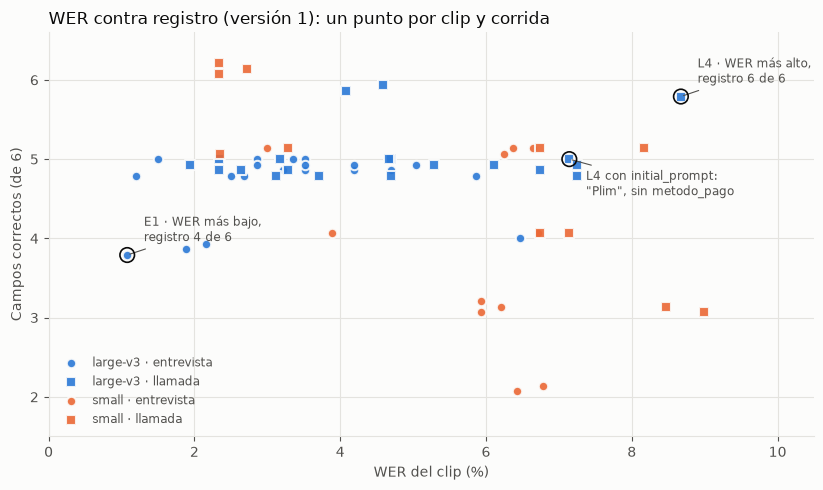

In [21]:
import matplotlib.pyplot as plt

TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLOR = {"large-v3": "#2a78d6", "small": "#eb6834"}   # paleta categórica de referencia, slots 1 y 2
FORMA = {"entrevista": "o", "llamada": "s"}
INITIAL_PROMPT = id_corrida(asr["modelo"], asr["compute_type"]["cuda"], "cuda", "initial_prompt")


def dibujar(puntos, destacar, ruta, titulo):
    """Un punto por clip y corrida; `destacar` es {(corrida, clip): (texto, desplazamiento vertical de la etiqueta)}."""
    fig, ax = plt.subplots(figsize=(8.5, 5), facecolor=FONDO)
    ax.set_facecolor(FONDO)
    desplazamiento = {c: (i - (len(ORDEN) - 2) / 2) * 0.07 for i, c in enumerate(ORDEN[1:])}  # separa puntos con el mismo valor
    for (modelo, tarea), g in puntos.groupby(["modelo", "tarea"]):
        ax.scatter(g["wer"] * 100, g["campos_correctos"] + g["corrida"].map(desplazamiento), s=46, marker=FORMA[tarea],
                   color=COLOR[modelo], edgecolor=FONDO, linewidth=1.5, alpha=0.9, label=f"{modelo} · {tarea}", zorder=3)
    for (corrida, clip), (texto, dy) in destacar.items():
        p = puntos[(puntos["corrida"] == corrida) & (puntos["clip"] == clip)].iloc[0]
        x, y = p["wer"] * 100, p["campos_correctos"] + desplazamiento[corrida]
        ax.scatter([x], [y], s=110, facecolor="none", edgecolor=TINTA, linewidth=1.2, zorder=4)
        ax.annotate(texto, (x, y), xytext=(12, dy), textcoords="offset points",
                    fontsize=8.5, color=TINTA_2, arrowprops=dict(arrowstyle="-", color=TINTA_2, linewidth=0.8))
    ax.set_xlabel("WER del clip (%)", color=TINTA_2)
    ax.set_ylabel("Campos correctos (de 6)", color=TINTA_2)
    ax.set_yticks(range(2, 7))
    ax.set_ylim(1.5, 6.6)
    ax.set_xlim(0, puntos["wer"].max() * 100 + 1.5)
    ax.grid(color=REJILLA, linewidth=0.8, zorder=0)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(REJILLA)
    ax.tick_params(colors=TINTA_2)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12)
    ax.legend(frameon=False, fontsize=8.5, labelcolor=TINTA_2, loc="lower left")
    fig.tight_layout()
    fig.savefig(ruta, dpi=150, facecolor=FONDO)
    plt.show()


dibujar(puntos, {(PRINCIPAL, "e1"): ("E1 · WER más bajo,\nregistro 4 de 6", 10),
                 (PRINCIPAL, "l4"): ("L4 · WER más alto,\nregistro 6 de 6", 10),
                 (INITIAL_PROMPT, "l4"): ("L4 con initial_prompt:\n\"Plim\", sin metodo_pago", -26)},
        rutas["figura_wer_registro_v1"], "WER contra registro (versión 1): un punto por clip y corrida")

Cada fila de puntos es un valor entero (2 a 6 campos). Dentro de una fila, los puntos de distintas corridas se separan un poco en vertical para que no se tapen; la tabla de arriba tiene los valores exactos.

### 3.1 Los dos casos

- **WER alto** es el cuartil superior de los 62 puntos y **WER bajo**, el inferior.
- **Registro perfecto** es 6 de 6; **registro roto**, 4 de 6 o menos (dos campos o más mal).

Se buscan primero en la corrida principal y después en todas.

In [22]:
def buscar_casos(puntos):
    """Los clips con WER alto y registro perfecto y con WER bajo y registro roto; devuelve la corrida principal."""
    q1, q3 = puntos["wer"].quantile([0.25, 0.75])
    print(f"WER bajo: <= {q1:.2%}   WER alto: >= {q3:.2%}")
    alto_perfecto = puntos[(puntos["wer"] >= q3) & (puntos["campos_correctos"] == 6)]
    bajo_roto = puntos[(puntos["wer"] <= q1) & (puntos["campos_correctos"] <= 4)]
    print("\nWER alto y registro perfecto:")
    display(alto_perfecto[["corrida", "clip", "wer", "campos_correctos"]].round(4))
    print("WER bajo y registro roto:")
    display(bajo_roto[["corrida", "clip", "wer", "campos_correctos"]].round(4))
    return puntos[puntos["corrida"] == PRINCIPAL].sort_values("wer")[["clip", "wer", "campos_correctos"]].round(4).reset_index(drop=True)


buscar_casos(puntos)

WER bajo: <= 2.86%   WER alto: >= 6.42%

WER alto y registro perfecto:


,corrida,clip,wer,campos_correctos
8,large-v3_float16_cuda_hotwords,l4,0.0867,6


WER bajo y registro roto:


,corrida,clip,wer,campos_correctos
0,large-v3_float16_cuda_hotwords,e1,0.0108,4
20,large-v3_float16_cuda_sin-glosario,e1,0.0189,4
30,large-v3_int8_cuda_sin-glosario,e1,0.0216,4


,clip,wer,campos_correctos
0,e1,0.0108,4
1,e2,0.0120,5
2,e5,0.0250,5
3,e3,0.0268,5
4,l1,0.0311,5
5,l5,0.0370,5
6,l2,0.0469,5
7,e4,0.0586,5
8,l3,0.0725,5
9,l4,0.0867,6


**Los dos existen, y en la misma corrida principal.** Ordenados por WER, sus clips quedan casi al revés que por registro:

- **E1: el WER más bajo de la corrida (1.08 %) y el peor registro (4 de 6).** Whisper oyó casi todo bien, pero escribió "6.500" y "semi-senior". El WER no los cuenta como error, porque la normalización quita el separador y el guion. La regla sí: pierde la pretensión y corta el puesto en "semi".
- **L4: el WER más alto de la corrida (8.67 %) y el único registro perfecto (6 de 6).** Casi todo su WER es una frase entera repetida por Whisper ("Es un edificio de oficinas, que deja el pedido en recepción", dos veces). Esas palabras de más no están en ningún campo.

Los dos casos salen del audio limpio, así que no hizo falta buscarlos en la escalera de degradación (`04_degradacion`). Allí la pregunta sigue abierta en la otra dirección: cuánto WER aguanta cada campo antes de romperse.

### 3.2 El caso de L4: initial_prompt y "Plim"

El mismo clip con los tres mecanismos de glosario. Con `initial_prompt` el WER es **menor** que con `hotwords`, y sin embargo es la única de las tres en que el registro se rompe: un solo error, "Plim" en lugar de "Plin", deja vacío `metodo_pago`.

In [23]:
filas = []
for mecanismo in [None, *asr["glosario_mecanismos_comparacion"]]:
    corrida = id_corrida(asr["modelo"], asr["compute_type"]["cuda"], "cuda", mecanismo)
    fila = puntos[(puntos["corrida"] == corrida) & (puntos["clip"] == "l4")].iloc[0]
    filas.append({"glosario": mecanismo or "sin", "wer_l4": round(fila["wer"], 4), "campos_correctos": fila["campos_correctos"],
                  "metodo_pago": extraidos[corrida, "l4"]["metodo_pago"]["valor"],
                  "transcripcion": contexto(textos[corrida]["l4"], "¿Cómo paga", 0, 25)})
pd.DataFrame(filas)

,glosario,wer_l4,campos_correctos,metodo_pago,transcripcion
0,sin,0.0408,6,plin,…¿Cómo paga? Con plin. Muy bien. Le …
1,initial_prompt,0.0714,5,NaN,"…¿Cómo paga? Con Plim. Muy bien, le …"
2,hotwords,0.0867,6,plin,…¿Cómo paga? Con Plin. Muy bien. Le …


### 3.3 ¿Correlacionan?

La correlación de Spearman entre el WER y los campos correctos, sobre los 62 puntos. No es una prueba formal: los puntos no son independientes (son los mismos 10 clips en 7 corridas) y casi toda la relación viene de separar `small` de `large-v3`.

In [24]:
def spearman(a, b):
    """Correlación de Spearman: Pearson sobre los rangos (con empates promediados)."""
    return a.rank().corr(b.rank())


print(f"Spearman, todos los puntos: {spearman(puntos['wer'], puntos['campos_correctos']):.2f}")
for modelo, g in puntos.groupby("modelo"):
    print(f"Spearman, solo {modelo}: {spearman(g['wer'], g['campos_correctos']):.2f} ({len(g)} puntos)")

Spearman, todos los puntos: -0.29
Spearman, solo large-v3: 0.33 (40 puntos)
Spearman, solo small: -0.54 (22 puntos)


Sobre todos los puntos la correlación es débil y negativa (−0.29), y casi toda viene de `small` (−0.54): un modelo peor oye mal palabras que sí están en los campos. **Dentro de `large-v3` el signo se invierte (+0.33)**: entre transcripciones buenas, más WER no significa peor registro.

### 3.4 Conclusión

**El WER no dice si el registro sirve.** En la corrida principal, el clip con menos WER tiene el peor registro y el que más WER tiene es el único perfecto. Lo que rompe un campo es un error pequeño en el lugar justo ("6.500", "semi-senior", "Plim"), y lo que más infla el WER (frases repetidas) puede no tocar ningún campo. Quien reporte solo el WER puede elegir el modelo correcto entre `small` y `large-v3`, pero no puede afirmar que el registro sea utilizable: eso hay que medirlo campo por campo.

## 4. Validación de pedidos con audio real (versión 1)

`validar_total`, `explicar_diferencia` y `diagnosticar` sobre las 5 llamadas de cada corrida. Ahora sí con las probabilidades de cada palabra que dio faster-whisper; el techo (las referencias) no las tiene y por eso nunca puede concluir `asr` (`05_validacion`, sección 4.1).

- **atrapado / no atrapado / falsa alarma / correcto**: veredicto del validador contra `trampa_total_errado` del ground truth. `no validable` cuando falta el precio de algún ítem.
- **explicación**: si la explicación contiene la causa real (`causa_error`), con la misma lectura de `05_validacion`.
- **diagnóstico**: `acierta` si coincide con el lado de la causa real (las tres del corpus son del hablante); `no decide` si es `indeterminado`.

In [25]:
from src.validacion import diagnosticar, explicar_diferencia, validar_total

llamadas = pd.read_csv(rutas["ground_truth_llamadas"]).set_index("clip")
causa_esperada = {  # causa_error del ground truth -> fragmento esperado en la explicación (como en 05_validacion)
    "Hablante: el vendedor olvidó el descuento": "se olvidó el descuento",
    "Hablante: el vendedor sumó mal": "suma mal llevada",
    "Hablante: el vendedor omitió una gaseosa": "se omitió una unidad de gaseosa",
}


def veredicto(errado, cuadra):
    if cuadra is None:
        return "no validable"
    if errado:
        return "atrapado" if not cuadra else "no atrapado"
    return "falsa alarma" if not cuadra else "correcto"


def validar(extraidos):
    """Validación de las llamadas de cada corrida, con las reglas vigentes."""
    filas = []
    for corrida in ORDEN:
        for clip in [c for c in sorted(textos[corrida]) if c.startswith("l")]:
            r, g = extraidos[corrida, clip], llamadas.loc[clip]
            palabras = (corridas[corrida][clip]["palabras"] if corrida != TECHO
                        else [{"word": w, "probability": None} for w in textos[TECHO][clip].split()])
            v, e, d = validar_total(r), explicar_diferencia(r), diagnosticar(r, palabras)
            causa = g["causa_error"] if isinstance(g["causa_error"], str) else None
            filas.append({
                "corrida": corrida, "clip": clip, "total_errado": g["trampa_total_errado"],
                "veredicto": veredicto(g["trampa_total_errado"], v["cuadra"]),
                "diferencia_gt": g["diferencia_total"], "diferencia_detectada": v["diferencia"],
                "explicacion": e["explicacion"],
                "explicacion_coincide": None if causa is None else causa_esperada[causa] in e["explicacion"],
                "diagnostico": d["diagnostico"],
                "diagnostico_vs_causa": None if causa is None else ("no decide" if d["diagnostico"] == "indeterminado"
                                        else "acierta" if d["diagnostico"] == causa.split(":")[0].lower() else "se equivoca"),
                "probabilidad_minima": d["senales"].get("probabilidad_minima"), "razon": d["razon"],
            })
    return pd.DataFrame(filas)


with con_reglas(VERSION_1):
    validacion = validar(extraidos)
validacion[validacion["corrida"] == PRINCIPAL].drop(columns="corrida").set_index("clip")

,total_errado,veredicto,diferencia_gt,diferencia_detectada,explicacion,explicacion_coincide,diagnostico,diagnostico_vs_causa,probabilidad_minima,razon
clip,,,,,,,,,,
l1,False,correcto,0,0.0,cuadra,None,NaN,NaN,NaN,el total cuadra: no hay nada que diagnosticar
l2,True,atrapado,5,5.0,se olvidó el descuento de promo app (5),True,hablante,acierta,0.8184,todas las palabras numéricas con probabilidad >= 0.6 (mínima 0.82); no descarta al ASR por sí sola; el total 95 se dice 2 veces: es poco probable que el ASR se equivoque igual dos veces; explicación: se olvidó el descuento de promo app (5) (humana)
l3,True,atrapado,10,10.0,salto de +10: suma mal llevada o número mal oído,True,indeterminado,no decide,0.8154,todas las palabras numéricas con probabilidad >= 0.6 (mínima 0.82); no descarta al ASR por sí sola; el total 121 se dice 1 vez; explicación: salto de +10: suma mal llevada o número mal oído (ambigua)
l4,False,correcto,0,0.0,cuadra,None,NaN,NaN,NaN,el total cuadra: no hay nada que diagnosticar
l5,True,atrapado,-9,-9.0,se omitió una unidad de gaseosa 1.5 litros (9),True,hablante,acierta,0.7700,todas las palabras numéricas con probabilidad >= 0.6 (mínima 0.77); no descarta al ASR por sí sola; el total 131 se dice 2 veces: es poco probable que el ASR se equivoque igual dos veces; explicación: se omitió una unidad de gaseosa 1.5 litros (9) (humana)


### 4.1 Todas las corridas

In [26]:
def resumir_validacion(validacion):
    errados = validacion[validacion["total_errado"]]
    return pd.DataFrame({
        "atrapados": errados.groupby("corrida")["veredicto"].apply(lambda s: f"{(s == 'atrapado').sum()}/{len(s)}"),
        "falsas_alarmas": validacion[~validacion["total_errado"]].groupby("corrida")["veredicto"].apply(lambda s: f"{(s == 'falsa alarma').sum()}/{len(s)}"),
        "no_validables": validacion.groupby("corrida")["veredicto"].apply(lambda s: (s == "no validable").sum()),
        "diferencia_igual_gt": errados.groupby("corrida").apply(lambda g: f"{(g['diferencia_gt'] == g['diferencia_detectada']).sum()}/{len(g)}"),
        "explicacion_coincide": errados.groupby("corrida")["explicacion_coincide"].apply(lambda s: f"{s.sum()}/{len(s)}"),
        "diagnostico_acierta": errados.groupby("corrida")["diagnostico_vs_causa"].apply(lambda s: f"{(s == 'acierta').sum()}/{len(s)}"),
        "diagnostico_no_decide": errados.groupby("corrida")["diagnostico_vs_causa"].apply(lambda s: (s == "no decide").sum()),
    }).reindex([c for c in ORDEN if c in set(validacion["corrida"])])


resumir_validacion(validacion)

,atrapados,falsas_alarmas,no_validables,diferencia_igual_gt,explicacion_coincide,diagnostico_acierta,diagnostico_no_decide
corrida,,,,,,,
referencias,3/3,0/2,0,3/3,3/3,2/3,1.0
large-v3_float16_cuda_hotwords,3/3,0/2,0,3/3,3/3,2/3,1.0
large-v3_float16_cuda_sin-glosario,3/3,0/2,0,3/3,3/3,2/3,1.0
large-v3_int8_cuda_sin-glosario,3/3,0/2,0,3/3,3/3,2/3,1.0
large-v3_float16_cuda_initial_prompt,3/3,0/2,0,3/3,3/3,2/3,1.0
small_float16_cuda_sin-glosario,2/3,0/2,1,1/3,1/3,0/3,2.0
small_int8_cuda_sin-glosario,2/3,0/2,1,2/3,2/3,0/3,2.0
small_int8_cpu_sin-glosario,NaN,0/1,0,NaN,NaN,NaN,NaN


In [27]:
validacion[validacion["corrida"].str.startswith("small") & validacion["total_errado"]][
    ["corrida", "clip", "veredicto", "diferencia_gt", "diferencia_detectada", "explicacion", "diagnostico", "razon"]]

,corrida,clip,veredicto,diferencia_gt,diferencia_detectada,explicacion,diagnostico,razon
26,small_float16_cuda_sin-glosario,l2,atrapado,5,5.0,se olvidó el descuento de promo app (5),indeterminado,"conflicto entre señales; palabra numérica con probabilidad baja: '95,' = 0.32 < 0.6; el total 95 se dice 2 veces: es poco probable que el ASR se equivoque igual dos veces; explicación: se olvidó el descuento de promo app (5) (humana)"
27,small_float16_cuda_sin-glosario,l3,atrapado,10,22.0,sin explicación,asr,palabra numérica con probabilidad baja: 'ciento' = 0.00 < 0.6; el total 121 se dice 1 vez; explicación: sin explicación
29,small_float16_cuda_sin-glosario,l5,no validable,-9,NaN,no validable,indeterminado,no se puede validar: falta el precio de algún ítem
31,small_int8_cuda_sin-glosario,l2,atrapado,5,5.0,se olvidó el descuento de promo app (5),indeterminado,"conflicto entre señales; palabra numérica con probabilidad baja: '95,' = 0.49 < 0.6; el total 95 se dice 2 veces: es poco probable que el ASR se equivoque igual dos veces; explicación: se olvidó el descuento de promo app (5) (humana)"
32,small_int8_cuda_sin-glosario,l3,atrapado,10,10.0,salto de +10: suma mal llevada o número mal oído,asr,palabra numérica con probabilidad baja: 'ciento' = 0.00 < 0.6; el total 121 se dice 1 vez; explicación: salto de +10: suma mal llevada o número mal oído (ambigua)
34,small_int8_cuda_sin-glosario,l5,no validable,-9,NaN,no validable,indeterminado,no se puede validar: falta el precio de algún ítem


**Qué atrapó.**

- **Corrida principal: lo mismo que el techo.** Atrapa los 3 totales errados (L2, L3 y L5) sin falsas alarmas en L1 ni en L4, y la diferencia es exactamente la del ground truth. La explicación contiene la causa real en las tres: en L2 (descuento olvidado) y en L5 (gaseosa omitida) es de tipo humana y el diagnóstico es `hablante`; en L3 (+10) es ambigua ("suma mal llevada o número mal oído") y el diagnóstico queda `indeterminado`, como con las referencias. Diagnóstico: 2 de 3 aciertan y 1 no decide; ninguno se equivoca.
- **Las probabilidades no cambian el resultado con `large-v3`.** La mínima entre las palabras numéricas está entre 0.74 y 0.85 en todas sus corridas, por encima del umbral de 0.6, así que no hay señal de ASR y las conclusiones son las del techo. Es lo esperado: en estas llamadas los errores son del hablante.
- **Con `small` aparecen errores del ASR encima de los del hablante.**
  - **L3:** "haciosas" en lugar de "gaseosas" hace que en float16 el ítem desaparezca del pedido. La diferencia pasa de +10 a +22 (los 10 del vendedor más las 3 gaseosas de 4 soles), no hay explicación simple y el diagnóstico es `asr`, por una palabra numérica con probabilidad 0.002. Con int8 el ítem sobrevive y la diferencia es +10, pero una probabilidad de 0.001 lleva el diagnóstico a `asr`. Las dos veces es incorrecto según el ground truth y aun así razonable: en esas transcripciones el ASR sí metió un error.
  - **L2:** una probabilidad baja (0.32 en float16 y 0.49 en int8) choca con la repetición del total y el diagnóstico queda `indeterminado`.
  - **L5:** dos errores de oído a la vez. "caciosas" hace que las gaseosas desaparezcan del pedido, y "cada pollo trae un mayonesa" (por "su mayonesa") agrega un pollo sin tamaño ni precio. El validador responde `no validable` en lugar de dar un veredicto falso.
- **No se ve aquí.** El caso en que el ASR oye mal un ítem y también el total, y todo sigue cuadrando, no aparece en el audio limpio. La escalera de degradación (`04_degradacion`) es la que puede producirlo.

## 5. Corrección de formato (versión 2)

La tabla de causas de la sección 2.5 mostró que, en la corrida principal, 8 de los 10 campos perdidos no venían de lo que Whisper oye sino de **cómo lo escribe**. La versión 2 corrige esos formatos en `src/normalizacion.py`, para que la extracción, la verificación y el WER usen la misma regla (paso 0 del docstring, `config.yaml → normalizacion`):

| Formato de Whisper | Antes (versión 1) | Versión 2 |
|---|---|---|
| Separador de miles: "6.500" | la extracción leía 6.5 y lo descartaba | 6500; "4.5" sigue siendo decimal |
| Símbolo de moneda: "$1.800", "S/ 6500" | el símbolo se perdía y la moneda caía en el valor por defecto (PEN) | "1800 dólares", "6500 soles" |
| Guion: "semi-senior" | el cargo se cortaba en "semi" | "semi senior", la forma del ground truth |
| Coma antes del número: "Calle Los Cedros, 245" | el patrón de dirección no encajaba | se acepta `,` o `.` entre el nombre de la vía y el número |

**Lo que no se corrige.** "Girón" por "Jirón" (L3) es un error de oído, no de formato: corregirlo sería adivinar lo que se dijo. E5 tampoco: el salario actual y la pretensión se dijeron en una sola oración.

**Cómo se probó.** Antes de tocar el código se escribieron, con su salida esperada, 15 casos de normalización y 13 variantes de extracción en frases que no son del corpus (`03_extraccion`, secciones 1.5 y 3.4; commit `2503caa`). Con la versión 1 acertaban 3 de 13 variantes y con la versión 2 aciertan las 13, sin ajustar ninguna. Las referencias siguen en 60 de 60, los 47 casos de normalización anteriores pasan y las 16 variantes de la 3.2 siguen en 12 de 16, con los mismos cuatro fallos.

### 5.1 La versión 1 es la del PR #7

Las tablas de las secciones 2 a 4 se comparan, carácter por carácter, con las que publicó el PR #7 (renombradas con el sufijo `_v1`).

In [28]:
def por_campo_de(registro):
    """Exactitud por corrida y campo, con el intervalo de Wilson: la tabla de registro_por_campo.csv."""
    tabla = registro.groupby(["corrida", "campo"], sort=False)["acierta"].agg(aciertos="sum", n="count").reset_index()
    tabla["exactitud"] = (tabla["aciertos"] / tabla["n"]).round(4)
    tabla["ic95_wilson"] = [tuple(round(x, 4) for x in intervalo_wilson(a, n)) for a, n in zip(tabla["aciertos"], tabla["n"])]
    return tabla


version_1 = {"registro_por_campo_v1": por_campo_de(registro), "registro_por_clip_v1": puntos.round(4),
             "validacion_audio_v1": validacion.drop(columns="razon")}
for clave, tabla in version_1.items():
    assert tabla.to_csv(index=False) == rutas[clave].read_text(encoding="utf-8"), f"la versión 1 ya no reproduce {clave}"
print("OK: las secciones 2 a 4 reproducen exactamente", ", ".join(rutas[c].name for c in version_1))

OK: las secciones 2 a 4 reproducen exactamente registro_por_campo_v1.csv, registro_por_clip_v1.csv, validacion_audio_v1.csv


### 5.2 Extraer y verificar con la versión 2

La misma función de la sección 2.1, ahora con las reglas vigentes. El techo tiene que seguir en 60 de 60.

In [29]:
extraidos_v2, registro_v2 = extraer_y_verificar()
assert registro_v2[registro_v2["corrida"] == TECHO]["acierta"].all(), "el techo sigue en 60 de 60"
pd.DataFrame({"version_1": registro.groupby("corrida")["acierta"].sum(), "version_2": registro_v2.groupby("corrida")["acierta"].sum(),
              "campos": registro_v2.groupby("corrida").size()}).reindex(ORDEN)

,version_1,version_2,campos
corrida,,,
referencias,60,60,60
large-v3_float16_cuda_hotwords,50,56,60
large-v3_float16_cuda_sin-glosario,50,56,60
large-v3_int8_cuda_sin-glosario,50,55,60
large-v3_float16_cuda_initial_prompt,49,54,60
small_float16_cuda_sin-glosario,40,43,60
small_int8_cuda_sin-glosario,44,47,60
small_int8_cpu_sin-glosario,9,10,12


### 5.3 Corrida principal: cada campo, antes y después

Aciertos sobre 5 clips por campo, con el intervalo de Wilson al 95 % de la versión 2.

In [30]:
antes, despues = exactitud(PRINCIPAL, registro), exactitud(PRINCIPAL, registro_v2)
principal_v2 = pd.DataFrame({
    "techo": exactitud(TECHO, registro_v2).apply(lambda f: f"{f['aciertos']}/{f['n']}", axis=1),
    "version_1": antes.apply(lambda f: f"{f['aciertos']}/{f['n']}", axis=1),
    "version_2": despues.apply(lambda f: f"{f['aciertos']}/{f['n']}", axis=1),
    "exactitud_v2": (despues["aciertos"] / despues["n"]).round(2),
    "ic95_wilson_v2": [tuple(round(x, 2) for x in intervalo_wilson(a, n)) for a, n in zip(despues["aciertos"], despues["n"])],
})
principal_v2.loc["total"] = [f"{t['aciertos'].sum()}/{t['n'].sum()}" for t in (exactitud(TECHO, registro_v2), antes, despues)] + [
    round(despues["aciertos"].sum() / despues["n"].sum(), 2),
    tuple(round(x, 2) for x in intervalo_wilson(despues["aciertos"].sum(), despues["n"].sum()))]
principal_v2

,techo,version_1,version_2,exactitud_v2,ic95_wilson_v2
campo,,,,,
anios_experiencia,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
ultimo_puesto,5/5,3/5,4/5,0.80,"(0.38, 0.96)"
tecnologias,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
pretension_salarial,5/5,1/5,4/5,0.80,"(0.38, 0.96)"
disponibilidad,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
nivel_ingles,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
items,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
promocion,5/5,5/5,5/5,1.00,"(0.57, 1.0)"
descuento,5/5,5/5,5/5,1.00,"(0.57, 1.0)"


In [31]:
entrevistas_principal = sorted(c for c in textos[PRINCIPAL] if c.startswith("e"))
monto = numericos["pretension_salarial (monto)"]
errores = error_absoluto([monto(gt[c]) for c in entrevistas_principal],
                         [monto({k: v["valor"] for k, v in extraidos_v2[PRINCIPAL, c].items()}) for c in entrevistas_principal])
print("macro F1 nivel_ingles:", round(macro_f1([gt[c]["nivel_ingles"] for c in entrevistas_principal],
                                               [extraidos_v2[PRINCIPAL, c]["nivel_ingles"]["valor"] for c in entrevistas_principal], clases), 2))
print("pretension_salarial, error absoluto por clip:", dict(zip(entrevistas_principal, errores)))
registro_v2[registro_v2["corrida"] == PRINCIPAL].pivot_table(index="acierta", columns="estado", values="clip", aggfunc="count", fill_value=0)

macro F1 nivel_ingles: 1.0
pretension_salarial, error absoluto por clip: {'e1': 0.0, 'e2': 0.0, 'e3': 0.0, 'e4': 0.0, 'e5': None}


estado,no_mencionado,sin_verificar,verificado
acierta,,,
False,2,0,2
True,0,1,55


En la corrida principal se recuperan 6 campos y el registro pasa de 50 a 56 de 60: la pretensión de E1, E2 y E3, el puesto de E1 y la dirección de L1 y L2. La pretensión sin valor baja de 3 de 5 clips a 1 (E5), y donde hay valor el error es 0. De los 4 campos que siguen errados, 2 quedan `verificado` (E4 y L5): la verificación sigue comprobando presencia, no corrección.

### 5.4 Todas las corridas

Aciertos por campo en cada corrida, con la versión 1 → la versión 2 donde cambian.

In [32]:
def antes_despues(corrida):
    a, d = exactitud(corrida, registro), exactitud(corrida, registro_v2)
    celdas = [f"{x}/{n}" if x == y else f"{x}/{n} → {y}/{n}" if n else "—" for x, y, n in zip(a["aciertos"], d["aciertos"], d["n"])]
    ta, td, tn = a["aciertos"].sum(), d["aciertos"].sum(), d["n"].sum()
    return celdas + [f"{ta}/{tn} → {td}/{tn}" if ta != td else f"{td}/{tn}"]


pd.DataFrame({c: antes_despues(c) for c in ORDEN}, index=[*CAMPOS, "total"])

,referencias,large-v3_float16_cuda_hotwords,large-v3_float16_cuda_sin-glosario,large-v3_int8_cuda_sin-glosario,large-v3_float16_cuda_initial_prompt,small_float16_cuda_sin-glosario,small_int8_cuda_sin-glosario,small_int8_cpu_sin-glosario
anios_experiencia,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1
ultimo_puesto,5/5,3/5 → 4/5,3/5 → 4/5,3/5 → 4/5,3/5 → 4/5,4/5,4/5,0/1
tecnologias,5/5,5/5,5/5,5/5,5/5,1/5,2/5,0/1
pretension_salarial,5/5,1/5 → 4/5,1/5 → 4/5,1/5 → 4/5,1/5 → 4/5,1/5 → 4/5,1/5 → 4/5,0/1 → 1/1
disponibilidad,5/5,5/5,5/5,5/5,5/5,3/5,4/5,1/1
nivel_ingles,5/5,5/5,5/5,5/5,5/5,4/5,4/5,1/1
items,5/5,5/5,5/5,5/5,5/5,3/5,4/5,1/1
promocion,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1
descuento,5/5,5/5,5/5,5/5,5/5,5/5,5/5,1/1
direccion_entrega,5/5,1/5 → 3/5,1/5 → 3/5,1/5 → 2/5,1/5 → 2/5,1/5,2/5,1/1


### 5.5 Lo que queda

Los campos que siguen fallando en la corrida principal, con el fragmento de la transcripción. El assert detiene la celda si la lista cambia.

In [33]:
fragmentos_v2 = {("e4", "ultimo_puesto"): "junior", ("e5", "pretension_salarial"): "gano",
                 ("l3", "direccion_entrega"): "Halcones", ("l5", "direccion_entrega"): "Laureles"}
quedan = registro_v2[(registro_v2["corrida"] == PRINCIPAL) & ~registro_v2["acierta"]]
assert set(zip(quedan["clip"], quedan["campo"])) == set(fragmentos_v2), sorted(zip(quedan["clip"], quedan["campo"]))
quedan.assign(audio=[contexto(textos[PRINCIPAL][c], fragmentos_v2[c, k], 45, 90) for c, k in zip(quedan["clip"], quedan["campo"])])[
    ["clip", "campo", "extraido", "ground_truth", "estado", "audio"]]

,clip,campo,extraido,ground_truth,estado,audio
79,e4,ultimo_puesto,Desarrollador front end junior,Desarrollador frontend junior,verificado,"…sto estás ahora? Soy desarrollador front-end junior en una startup de educación. Aprende más. Aunque ya llevo un año ahí, todavía figuro como…"
87,e5,pretension_salarial,None,7000 PEN,no_mencionado,"…Cuál es tu expectativa salarial? Actualmente gano 6200, pero mi pretensión es de 7000 soles brutos mensuales. Ok, ¿y cuántos años llevas en…"
105,l3,direccion_entrega,None,"Jirón Los Halcones 1034, interior 5, Jesús María",no_mencionado,"…aro. Sin costo. ¿A qué dirección? Girón, Los Halcones, 1043, interior 5. No, perdón, me equivoqué. Es 1034. Girón, Los Halcones, 1034, interior…"
117,l5,direccion_entrega,Avenida Los Laureles 2271,"Avenida Los Laureles 2271, bloque C, departamento 504, San Juan de Lurigancho",verificado,"…rfecto. Dirección de la entrega. Avenida Los Laureles 2271. Bloque C. Departamento 504, en San Juan del Urigancho. 2271. Bloque C. Departamento…"


In [34]:
fallan_v2 = registro_v2[(registro_v2["corrida"] != TECHO) & ~registro_v2["acierta"]]
fallan_v2.groupby(["clip", "campo"])["corrida"].agg(corridas="count", cuales=lambda s: ", ".join(sorted(s)))

corridas  \
clip campo                           
e1   tecnologias                 3   
     ultimo_puesto               3   
e2   tecnologias                 1   
e3   disponibilidad              1   
     tecnologias                 2   
e4   ultimo_puesto               4   
e5   disponibilidad              2   
     nivel_ingles                2   
     pretension_salarial         6   
     tecnologias                 2   
l2   direccion_entrega           4   
l3   direccion_entrega           6   
     items                       1   
l4   direccion_entrega           1   
     metodo_pago                 3   
l5   direccion_entrega           6   
     items                       2   
     metodo_pago                 2   

                                                                                                                                                                                                                            cuales  
clip campo                                                                                                                                                                                                                          
e1   tecnologias                                                                                                                        small_float16_cuda_sin-glosario, small_int8_cpu_sin-glosario, small_int8_cuda_sin-glosario  
     ultimo_puesto                                                                                                                      small_float16_cuda_sin-glosario, small_int8_cpu_sin-glosario, small_int8_cuda_sin-glosario  
e2   tecnologias                                                                                                                                                                                   small_float16_cuda_sin-glosario  
e3   disponibilidad                                                                                                                                                                                small_float16_cuda_sin-glosario  
     tecnologias                                                                                                                                                     small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
e4   ultimo_puesto                                                                       large-v3_float16_cuda_hotwords, large-v3_float16_cuda_initial_prompt, large-v3_float16_cuda_sin-glosario, large-v3_int8_cuda_sin-glosario  
e5   disponibilidad                                                                                                                                                  small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
     nivel_ingles                                                                                                                                                    small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
     pretension_salarial  large-v3_float16_cuda_hotwords, large-v3_float16_cuda_initial_prompt, large-v3_float16_cuda_sin-glosario, large-v3_int8_cuda_sin-glosario, small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
     tecnologias                                                                                                                                                     small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
l2   direccion_entrega                                                                        large-v3_float16_cuda_initial_prompt, large-v3_int8_cuda_sin-glosario, small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
l3   direccion_entrega    large-v3_float16_cuda_hotwords, large-v3_float16_cuda_initial_prompt, large-v3_float16_cuda_sin-glosario, large-v3_int8_cuda_sin-glosario, small_float16_cuda_sin-glosario, small_int8_cuda_sin-glosario  
     items                                                 

**Por qué quedan.**

| Campo | Causa | Tipo |
|---|---|---|
| `ultimo_puesto` de E4 | Whisper escribe "front-end" y el ground truth "frontend", junto. La regla pedida hace el guion equivalente al **espacio** ("front end"), que es lo que arregla "semi-senior" en E1, pero no a la palabra unida. Sigue `verificado`: "Desarrollador front end junior" está en la transcripción. | formato, fuera de la regla |
| `pretension_salarial` de E5 | "Actualmente gano 6200, pero mi pretensión es de 7000": salario actual y pretensión en una oración, y la regla descarta la oración entera. | lo que se dijo |
| `direccion_entrega` de L3 | "Girón, Los Halcones": "Girón" no es un tipo de vía. Es un error de oído y no se corrige. | ASR |
| `direccion_entrega` de L5 | "Avenida Los Laureles 2271. Bloque C. Departamento 504": Whisper pone un punto **después** del número, la oración se corta y los complementos se pierden. Además oye "San Juan del Urigancho". Sigue `verificado`, sin sus complementos. | formato y ASR |

En las otras corridas de `large-v3` aparecen los mismos cuatro y uno más: en `initial_prompt` e `int8`, L2 sale "Avenida Las Gardeñas", mal oído. En `small` siguen los errores de oído de la sección 2.6 ("semi-signor", "Postgre SQL", "haciosas").

### 5.6 Los dos clips del hallazgo, con la versión 2

La misma búsqueda de la sección 3.1, con el WER definitivo de la sección 1 y el registro de la versión 2.

In [35]:
puntos_v2 = unir_puntos(registro_v2, por_clip["wer"])
buscar_casos(puntos_v2)

WER bajo: <= 2.86%   WER alto: >= 6.42%

WER alto y registro perfecto:


,corrida,clip,wer,campos_correctos
8,large-v3_float16_cuda_hotwords,l4,0.0867,6
10,large-v3_float16_cuda_initial_prompt,e1,0.0647,6
55,small_int8_cuda_sin-glosario,e4,0.0664,6


WER bajo y registro roto:


,corrida,clip,wer,campos_correctos


,clip,wer,campos_correctos
0,e2,0.0090,6
1,e1,0.0108,6
2,e5,0.0250,5
3,e3,0.0268,6
4,l1,0.0311,6
5,l5,0.0370,5
6,l2,0.0469,6
7,e4,0.0586,5
8,l3,0.0725,5
9,l4,0.0867,6


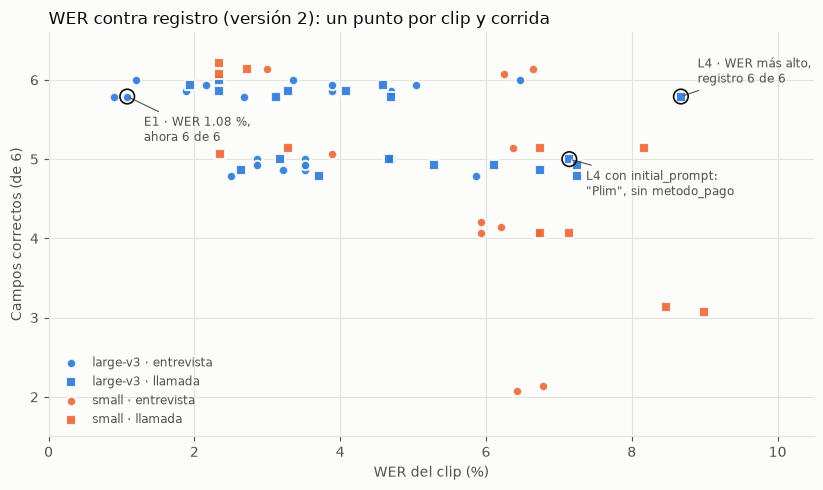

Spearman, todos los puntos: -0.54
Spearman, solo large-v3: -0.31 (40 puntos)
Spearman, solo small: -0.63 (22 puntos)


In [36]:
dibujar(puntos_v2, {(PRINCIPAL, "e1"): ("E1 · WER 1.08 %,\nahora 6 de 6", -32),
                    (PRINCIPAL, "l4"): ("L4 · WER más alto,\nregistro 6 de 6", 10),
                    (INITIAL_PROMPT, "l4"): ("L4 con initial_prompt:\n\"Plim\", sin metodo_pago", -26)},
        rutas["figura_wer_registro"], "WER contra registro (versión 2): un punto por clip y corrida")
print(f"Spearman, todos los puntos: {spearman(puntos_v2['wer'], puntos_v2['campos_correctos']):.2f}")
for modelo, g in puntos_v2.groupby("modelo"):
    print(f"Spearman, solo {modelo}: {spearman(g['wer'], g['campos_correctos']):.2f} ({len(g)} puntos)")

**Cambia uno de los dos casos.**

- **WER bajo y registro roto: ya no hay ninguno**, en ninguna de las 7 corridas. E1, el caso de la versión 1, pasa de 4 a 6 de 6 con el mismo WER (1.08 %): lo que rompía su registro era el formato ("6.500", "semi-senior"), y la versión 2 lo lee. En la corrida principal el peor registro es ahora 5 de 6.
- **WER alto y registro perfecto: sigue L4** (8.67 %, 6 de 6), por la misma frase repetida. Se suman E1 con `initial_prompt` (6.47 %) y E4 con `small` int8 (6.64 %).
- **"Plim" sigue.** L4 con `initial_prompt` tiene menos WER que con `hotwords` y pierde `metodo_pago`: es una palabra mal oída y la corrección no la toca.
- **La correlación se hace más clara.** Spearman pasa de −0.29 a −0.54 sobre los 62 puntos y, dentro de `large-v3`, de +0.33 a −0.31. No es una prueba formal: los puntos son los mismos 10 clips en 7 corridas.

**Qué queda de la conclusión de la 3.4.** El WER sigue sin decir, clip por clip, si el registro sirve: L4 tiene el WER más alto y el registro perfecto, y un solo "Plim" rompe un campo en una transcripción con menos WER. Pero el caso más llamativo de la versión 1, un clip casi perfecto en WER con dos campos rotos, era un defecto de las reglas y no del ASR. El WER no lo podía ver, porque la normalización borra el formato. Con reglas que leen cómo escribe Whisper, ese caso desaparece.

### 5.7 Validación de pedidos

La validación usa los ítems, la promoción y el total, que la corrección no toca. Se vuelve a correr con la versión 2 para comprobarlo.

In [37]:
validacion_v2 = validar(extraidos_v2)
pd.testing.assert_frame_equal(validacion_v2, validacion)
print("OK: la validación de las 7 corridas es idéntica con la versión 2")

OK: la validación de las 7 corridas es idéntica con la versión 2


Lo que atrapó la validación no cambia: en la corrida principal, los 3 totales errados atrapados, sin falsas alarmas, y el diagnóstico acierta 2 de 3 (L3 queda `indeterminado`). La sección 4 vale tal cual para la versión 2.

## 6. Task 2: curva de degradación

WER y exactitud por nivel.

*Pendiente.*

## 7. Lo que la muestra no permite afirmar

Tamaño de muestra, intervalos y limitaciones.

*Pendiente.*

## 8. Exportar para README y app

Las tablas finales, en `rutas.resultados_dir`:

- sección 1 (1.8): `metricas_transcripcion.csv` y `metricas_por_clip.csv`;
- con la versión 2 de las reglas (sección 5), que es la definitiva: `registro_por_campo.csv` (exactitud por campo y corrida, con el techo), `registro_por_clip.csv` (WER y campos correctos por clip y corrida), `validacion_audio.csv` (una fila por llamada y corrida) y el gráfico `wer_contra_registro.png`, que se escribe en la 5.6.

Las tablas de la versión 1 (`*_v1.csv`) son las del PR #7 y no se reescriben: la sección 5.1 comprueba que las secciones 2 a 4 las reproducen. Su gráfico, `wer_contra_registro_v1.png`, lo vuelve a dibujar la sección 3.

In [38]:
por_campo_de(registro_v2).to_csv(rutas["registro_por_campo"], index=False)
puntos_v2.round(4).to_csv(rutas["registro_por_clip"], index=False)
validacion_v2.drop(columns="razon").to_csv(rutas["validacion_audio"], index=False)
for clave in ("registro_por_campo", "registro_por_clip", "validacion_audio", "figura_wer_registro"):
    print("Escrito:", rutas[clave].relative_to(RAIZ))

Escrito: data/resultados/registro_por_campo.csv
Escrito: data/resultados/registro_por_clip.csv
Escrito: data/resultados/validacion_audio.csv
Escrito: data/resultados/wer_contra_registro.png
